---
## Stage 1 — Setup & Configuration

All imports up front, plus a single `CONFIG` dictionary so every hyperparameter used
later in the notebook lives in one place — makes the whole pipeline easy to re-run with
different settings without hunting through cells.

In [1]:
%pip install -q "seqeval>=1.2.2" "transformers>=4.44,<5" "datasets>=2.18" "pytorch-crf==0.7.2" "gradio>=4.44,<6" "accelerate>=0.26" matplotlib seaborn pandas scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
hf-gradio 0.4.1 requires gradio-client<3.0,>=2.0, but you have gradio-client 1.14.0 which is incompatible.
google-genai 2.12.1 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.12.3 which is incompatible.
python-fasthtml 0.14.14 requires starlette>=1.0.1, but you have starlette 0.52.1 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
google-adk 2.7.1 requires starlette<2,>=1.3.1, but you have starlette 0.52.1 which is incompatible.
Note: you may need to restar

In [2]:
import os
import json
import pickle
import shutil
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchcrf import CRF

from datasets import load_dataset, Dataset as HFDataset
from transformers import (
    AutoTokenizer, AutoModelForTokenClassification,
    Trainer, TrainingArguments, DataCollatorForTokenClassification,
)

from seqeval.metrics import classification_report, f1_score, precision_score, recall_score


I0000 00:00:1794574488.742299      50 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
CONFIG = {
    # reproducibility
    "random_state": 42,

    # word-level vocab (LSTM / BiLSTM / BiLSTM+CRF family)
    "embedding_dim": 100,
    "char_embedding_dim": 30,
    "char_hidden_dim": 25,
    "hidden_dim": 128,
    "max_len": 60,          # checked against the sentence-length distribution in Stage 2
    "max_word_len": 20,     # max characters per word for the char-level branch

    # RNN family training
    "rnn_epochs": 15,
    "patience": 3,
    "batch_size": 32,
    "learning_rate": 1e-3,
    "grad_clip": 5.0,

    # transformer fine-tuning
    "transformer_name": "distilbert-base-cased",
    "transformer_epochs": 3,
    "transformer_lr": 2e-5,
    "transformer_train_batch": 16,
    "transformer_eval_batch": 32,

    # deployment
    "save_dir": "deployment_bundle",
    "glove_path": "/kaggle/input/glove6b100dtxt/glove.6B.100d.txt",
}

np.random.seed(CONFIG["random_state"])
torch.manual_seed(CONFIG["random_state"])
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
print(CONFIG)

Device: cuda
{'random_state': 42, 'embedding_dim': 100, 'char_embedding_dim': 30, 'char_hidden_dim': 25, 'hidden_dim': 128, 'max_len': 60, 'max_word_len': 20, 'rnn_epochs': 15, 'patience': 3, 'batch_size': 32, 'learning_rate': 0.001, 'grad_clip': 5.0, 'transformer_name': 'distilbert-base-cased', 'transformer_epochs': 3, 'transformer_lr': 2e-05, 'transformer_train_batch': 16, 'transformer_eval_batch': 32, 'save_dir': 'deployment_bundle', 'glove_path': '/kaggle/input/glove6b100dtxt/glove.6B.100d.txt'}


---
## Stage 2 — Data Loading & Exploration

Goals here: confirm the tag scheme, look at how sentence length is distributed (drives
`max_len` above), and check how balanced the entity types are — a skewed distribution
(e.g. far fewer `MISC` examples) is exactly the kind of thing that later shows up as a
weak per-entity F1 in Stage 6.

In [4]:
dataset = load_dataset("lhoestq/conll2003")  # parquet mirror, no loading script -> works on datasets>=4.x

# The parquet conversion stores ner_tags as plain int64 (no ClassLabel names attached),
# so the label list is hardcoded here -- this is the standard CoNLL-2003 IOB2 tag order
# (verified against the dataset's own tag ids, e.g. "EU"->3 (B-ORG), "German"->7 (B-MISC)).
label_list = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
id2label = {i: l for i, l in enumerate(label_list)}
label2id = {l: i for i, l in enumerate(label_list)}
NUM_LABELS = len(label_list)

print("Labels:", label_list)
print({split: len(dataset[split]) for split in dataset})
dataset["train"][0]

dataset_infos.json: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/281k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
{'train': 14041, 'validation': 3250, 'test': 3453}


{'id': '0',
 'tokens': ['EU',
  'rejects',
  'German',
  'call',
  'to',
  'boycott',
  'British',
  'lamb',
  '.'],
 'pos_tags': [22, 42, 16, 21, 35, 37, 16, 21, 7],
 'chunk_tags': [11, 21, 11, 12, 21, 22, 11, 12, 0],
 'ner_tags': [3, 0, 7, 0, 0, 0, 7, 0, 0]}

In [5]:
def to_tokens_and_tags(example):
    return {
        "tokens": example["tokens"],
        "tags": [label_list[t] for t in example["ner_tags"]],
    }

sample = to_tokens_and_tags(dataset["train"][0])
pd.DataFrame({"token": sample["tokens"], "tag": sample["tags"]}).T

,0,1,2,3,4,5,6,7,8
token,EU,rejects,German,call,to,boycott,British,lamb,.
tag,B-ORG,O,B-MISC,O,O,O,B-MISC,O,O


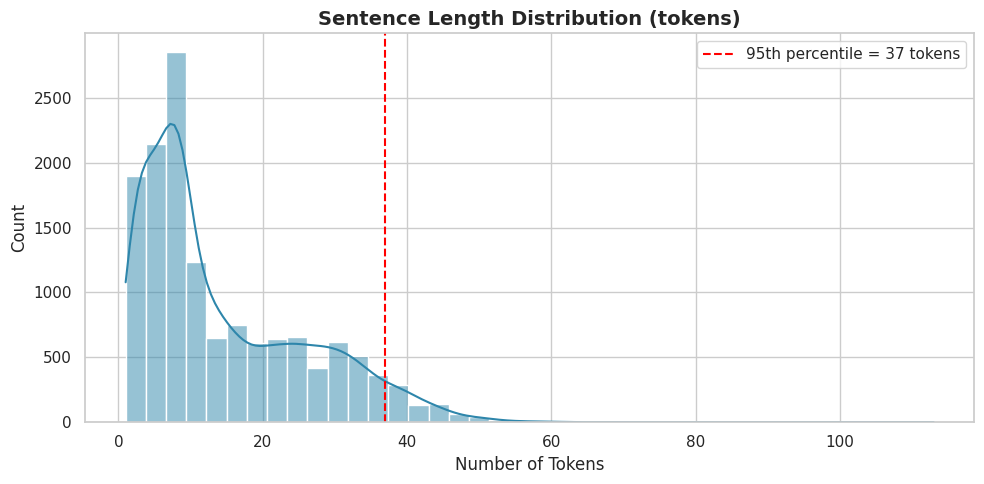

count    14041.000000
mean        14.501887
std         11.602756
min          1.000000
25%          6.000000
50%         10.000000
75%         22.000000
max        113.000000
dtype: float64


In [6]:
### Sentence length distribution -> informs CONFIG["max_len"]
sent_lengths = [len(ex["tokens"]) for ex in dataset["train"]]

plt.figure(figsize=(10, 5))
sns.histplot(sent_lengths, bins=40, kde=True, color="#2E86AB")
p95 = np.percentile(sent_lengths, 95)
plt.axvline(p95, color="red", linestyle="--", label=f"95th percentile = {p95:.0f} tokens")
plt.title("Sentence Length Distribution (tokens)", fontsize=14, fontweight="bold")
plt.xlabel("Number of Tokens"); plt.legend()
plt.tight_layout(); plt.savefig("length_distribution.png", dpi=150); plt.show()

print(pd.Series(sent_lengths).describe())

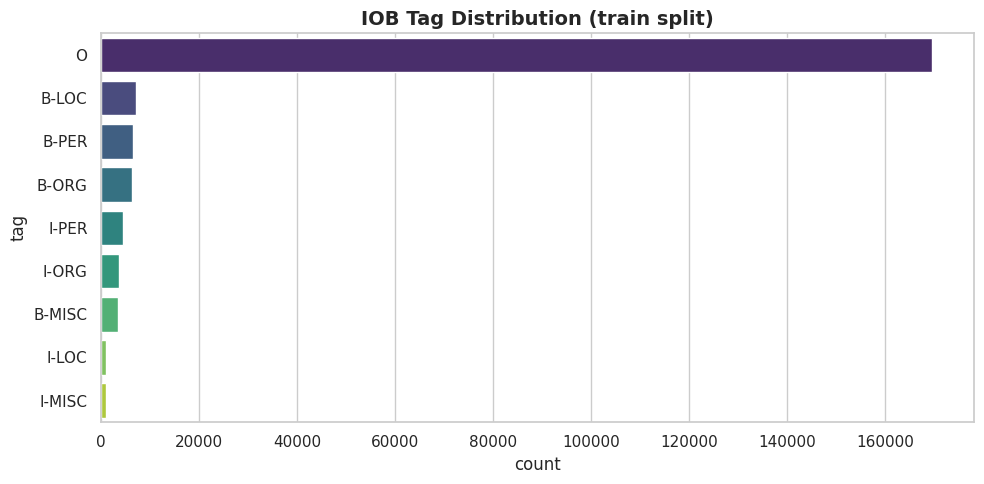

Entity-type totals (B+I combined): {'ORG': 10025, 'MISC': 4593, 'PER': 11128, 'LOC': 8297}


In [7]:
### Entity tag distribution
all_tags = [label_list[t] for ex in dataset["train"] for t in ex["ner_tags"]]
tag_counts = Counter(all_tags)
tag_df = pd.DataFrame(tag_counts.items(), columns=["tag", "count"]).sort_values("count", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=tag_df, x="count", y="tag", hue="tag", palette="viridis", legend=False)
plt.title("IOB Tag Distribution (train split)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig("tag_distribution.png", dpi=150); plt.show()

entity_totals = Counter()
for ex in dataset["train"]:
    for t in ex["ner_tags"]:
        tag = label_list[t]
        if tag != "O":
            entity_totals[tag.split("-")[-1]] += 1
print("Entity-type totals (B+I combined):", dict(entity_totals))

`O` dominates by far (most tokens aren't part of any entity), and among entity types
`MISC` tends to be the smallest — worth watching in the per-entity F1 table in Stage 6,
since it gets the least training signal.

---
## Stage 3 — Preprocessing

Two parallel preprocessing paths are needed:

1. **Word-level path** (for LSTM / BiLSTM / BiLSTM+CRF): build a word vocabulary from
   the training split, a **character vocabulary** for the char-level branch (handles
   OOV words like rare names via sub-word character patterns instead of an `<UNK>`
   token), and load pretrained **GloVe** embeddings where available.
2. **Subword path** (for the transformer): use the model's own tokenizer, and
   **align labels to subwords** — a word split into multiple subword pieces only keeps
   its label on the first piece; the rest are masked with `-100` so the loss ignores them.

In [8]:
### Word + character vocab (built ONLY on the training split to avoid leakage)
PAD, UNK = "<PAD>", "<UNK>"

word_counter = Counter(w.lower() for ex in dataset["train"] for w in ex["tokens"])
word2idx = {PAD: 0, UNK: 1}
for w in word_counter:
    word2idx[w] = len(word2idx)

char_counter = Counter(c for ex in dataset["train"] for w in ex["tokens"] for c in w)
char2idx = {PAD: 0, UNK: 1}
for c in char_counter:
    char2idx[c] = len(char2idx)

print(f"Word vocab size: {len(word2idx)}  |  Char vocab size: {len(char2idx)}")

Word vocab size: 21011  |  Char vocab size: 86


In [9]:
### Pretrained GloVe embeddings (falls back to random init if the file isn't present)
GLOVE_PATH = CONFIG["glove_path"]  # adjust to your Kaggle dataset path

def build_embedding_matrix(word2idx, dim, glove_path):
    matrix = np.random.normal(0, 0.1, (len(word2idx), dim)).astype(np.float32)
    matrix[0] = np.zeros(dim)  # <PAD>
    if os.path.exists(glove_path):
        found = 0
        with open(glove_path, encoding="utf8") as f:
            for line in f:
                parts = line.rstrip().split(" ")
                word, vec = parts[0], parts[1:]
                if word in word2idx:
                    matrix[word2idx[word]] = np.asarray(vec, dtype=np.float32)
                    found += 1
        print(f"GloVe coverage: {found}/{len(word2idx)} words ({found/len(word2idx)*100:.1f}%)")
    else:
        print("GloVe file not found — attach a GloVe Kaggle dataset and update GLOVE_PATH. "
              "Falling back to randomly-initialised (trainable) embeddings.")
    return matrix

embedding_matrix = build_embedding_matrix(word2idx, CONFIG["embedding_dim"], GLOVE_PATH)

GloVe file not found — attach a GloVe Kaggle dataset and update GLOVE_PATH. Falling back to randomly-initialised (trainable) embeddings.


In [10]:
### PyTorch Dataset for the word-level (LSTM / BiLSTM / BiLSTM+CRF) family
class NERWordDataset(Dataset):
    def __init__(self, hf_split, word2idx, char2idx, label2id, max_len, max_word_len):
        self.data = hf_split
        self.word2idx, self.char2idx, self.label2id = word2idx, char2idx, label2id
        self.max_len, self.max_word_len = max_len, max_word_len

    def __len__(self):
        return len(self.data)

    def _encode_word(self, w):
        return self.word2idx.get(w.lower(), self.word2idx[UNK])

    def _encode_chars(self, w):
        ids = [self.char2idx.get(c, self.char2idx[UNK]) for c in w[: self.max_word_len]]
        ids += [0] * (self.max_word_len - len(ids))
        return ids

    def __getitem__(self, idx):
        ex = self.data[idx]
        tokens, tags = ex["tokens"][: self.max_len], ex["ner_tags"][: self.max_len]

        word_ids = [self._encode_word(w) for w in tokens]
        char_ids = [self._encode_chars(w) for w in tokens]
        label_ids = list(tags)

        pad_len = self.max_len - len(tokens)
        mask = [1] * len(tokens) + [0] * pad_len
        word_ids += [0] * pad_len
        char_ids += [[0] * self.max_word_len] * pad_len
        label_ids += [0] * pad_len  # padded positions excluded via `mask` at loss/decode time

        return {
            "word_ids": torch.tensor(word_ids, dtype=torch.long),
            "char_ids": torch.tensor(char_ids, dtype=torch.long),
            "labels": torch.tensor(label_ids, dtype=torch.long),
            "mask": torch.tensor(mask, dtype=torch.bool),
        }

train_word_ds = NERWordDataset(dataset["train"], word2idx, char2idx, label2id,
                                CONFIG["max_len"], CONFIG["max_word_len"])
val_word_ds = NERWordDataset(dataset["validation"], word2idx, char2idx, label2id,
                              CONFIG["max_len"], CONFIG["max_word_len"])
test_word_ds = NERWordDataset(dataset["test"], word2idx, char2idx, label2id,
                               CONFIG["max_len"], CONFIG["max_word_len"])

train_loader = DataLoader(train_word_ds, batch_size=CONFIG["batch_size"], shuffle=True)
val_loader = DataLoader(val_word_ds, batch_size=CONFIG["batch_size"])
test_loader = DataLoader(test_word_ds, batch_size=CONFIG["batch_size"])

print("Batches -> train:", len(train_loader), " val:", len(val_loader), " test:", len(test_loader))

Batches -> train: 439  val: 102  test: 108


In [11]:
### Subword tokenization + label alignment (transformer path)
hf_tokenizer = AutoTokenizer.from_pretrained(CONFIG["transformer_name"])

def tokenize_and_align_labels(examples):
    tokenized = hf_tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
    all_labels = []
    for i, tags in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)                       # special tokens (CLS/SEP)
            elif word_idx != previous_word_idx:
                label_ids.append(tags[word_idx])              # first subword keeps the label
            else:
                label_ids.append(-100)                        # later subwords are masked
            previous_word_idx = word_idx
        all_labels.append(label_ids)
    tokenized["labels"] = all_labels
    return tokenized

tokenized_ds = dataset.map(tokenize_and_align_labels, batched=True,
                            remove_columns=dataset["train"].column_names)
data_collator = DataCollatorForTokenClassification(tokenizer=hf_tokenizer)
tokenized_ds

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 3453
    })
})

---
## Stage 4 — LSTM, BiLSTM & BiLSTM+CRF (built from scratch)

All three share the same **word embedding + char-level BiLSTM** input representation
(concatenated per token), so the comparison in Stage 6 isolates the effect of
(a) bidirectionality and (b) the CRF layer, rather than confounding it with different
input features.

- **Char-level BiLSTM branch**: encodes each word's characters, letting the model
  recognise patterns like capitalisation or suffixes for words *not* in the GloVe
  vocabulary (the OOV handling required by the project spec).
- **CRF layer** (3rd model only): learns a transition matrix between tags — e.g. it can
  learn that `I-PER` almost never legally follows `B-ORG` — so it corrects
  boundary-level mistakes a plain softmax-per-token classifier can make.

In [12]:
class CharEncoder(nn.Module):
    """Per-word character-level BiLSTM -> fixed-size char representation."""
    def __init__(self, char_vocab_size, char_emb_dim, char_hidden_dim):
        super().__init__()
        self.char_embedding = nn.Embedding(char_vocab_size, char_emb_dim, padding_idx=0)
        self.char_lstm = nn.LSTM(char_emb_dim, char_hidden_dim, batch_first=True, bidirectional=True)

    def forward(self, char_ids):
        # char_ids: (batch, seq_len, max_word_len)
        b, s, w = char_ids.shape
        char_ids = char_ids.reshape(b * s, w)
        lengths = (char_ids != 0).sum(dim=1).clamp(min=1).cpu()
        emb = self.char_embedding(char_ids)
        packed = nn.utils.rnn.pack_padded_sequence(emb, lengths, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.char_lstm(packed)
        char_repr = torch.cat([h_n[0], h_n[1]], dim=-1)          # (b*s, 2*char_hidden_dim)
        return char_repr.view(b, s, -1)


class BaseTagger(nn.Module):
    """Shared embedding stack; subclasses plug in the recurrent + output layers."""
    def __init__(self, embedding_matrix, char_vocab_size, num_labels, cfg, bidirectional):
        super().__init__()
        vocab_size, emb_dim = embedding_matrix.shape
        self.word_embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.word_embedding.weight.data.copy_(torch.tensor(embedding_matrix))

        self.char_encoder = CharEncoder(char_vocab_size, cfg["char_embedding_dim"], cfg["char_hidden_dim"])
        combined_dim = emb_dim + 2 * cfg["char_hidden_dim"]

        self.lstm = nn.LSTM(combined_dim, cfg["hidden_dim"], batch_first=True, bidirectional=bidirectional)
        self.dropout = nn.Dropout(0.4)
        out_dim = cfg["hidden_dim"] * (2 if bidirectional else 1)
        self.fc = nn.Linear(out_dim, num_labels)

    def _features(self, word_ids, char_ids):
        word_emb = self.word_embedding(word_ids)
        char_repr = self.char_encoder(char_ids)
        combined = torch.cat([word_emb, char_repr], dim=-1)
        lstm_out, _ = self.lstm(combined)
        return self.fc(self.dropout(lstm_out))


class LSTMTagger(BaseTagger):
    def __init__(self, embedding_matrix, char_vocab_size, num_labels, cfg):
        super().__init__(embedding_matrix, char_vocab_size, num_labels, cfg, bidirectional=False)

    def forward(self, word_ids, char_ids, labels=None, mask=None):
        emissions = self._features(word_ids, char_ids)
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss(reduction="none")
            loss = loss_fct(emissions.view(-1, emissions.size(-1)), labels.view(-1))
            loss = (loss * mask.view(-1)).sum() / mask.sum()
            return loss, emissions
        return None, emissions


class BiLSTMTagger(BaseTagger):
    def __init__(self, embedding_matrix, char_vocab_size, num_labels, cfg):
        super().__init__(embedding_matrix, char_vocab_size, num_labels, cfg, bidirectional=True)

    def forward(self, word_ids, char_ids, labels=None, mask=None):
        emissions = self._features(word_ids, char_ids)
        if labels is not None:
            loss_fct = nn.CrossEntropyLoss(reduction="none")
            loss = loss_fct(emissions.view(-1, emissions.size(-1)), labels.view(-1))
            loss = (loss * mask.view(-1)).sum() / mask.sum()
            return loss, emissions
        return None, emissions


class BiLSTMCRFTagger(BaseTagger):
    def __init__(self, embedding_matrix, char_vocab_size, num_labels, cfg):
        super().__init__(embedding_matrix, char_vocab_size, num_labels, cfg, bidirectional=True)
        self.crf = CRF(num_labels, batch_first=True)

    def forward(self, word_ids, char_ids, labels=None, mask=None):
        emissions = self._features(word_ids, char_ids)
        if labels is not None:
            loss = -self.crf(emissions, labels, mask=mask, reduction="mean")
            return loss, emissions
        decoded = self.crf.decode(emissions, mask=mask)
        return None, decoded

In [13]:
### Shared training / evaluation loop
def run_epoch(model, loader, optimizer=None, is_crf=False):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, n_batches = 0.0, 0

    with torch.set_grad_enabled(training):
        for batch in loader:
            word_ids = batch["word_ids"].to(device)
            char_ids = batch["char_ids"].to(device)
            labels = batch["labels"].to(device)
            mask = batch["mask"].to(device)

            loss, _ = model(word_ids, char_ids, labels=labels, mask=mask)
            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["grad_clip"])
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1
    return total_loss / n_batches


@torch.no_grad()
def predict_tags(model, loader, is_crf):
    model.eval()
    all_true, all_pred = [], []
    for batch in loader:
        word_ids = batch["word_ids"].to(device)
        char_ids = batch["char_ids"].to(device)
        labels = batch["labels"]
        mask = batch["mask"].to(device)

        _, out = model(word_ids, char_ids, labels=None, mask=mask)
        lengths = batch["mask"].sum(dim=1).tolist()

        if is_crf:
            pred_seqs = out  # list of lists already trimmed to valid length by CRF.decode
        else:
            pred_ids = out.argmax(-1).cpu()
            pred_seqs = [pred_ids[i, : lengths[i]].tolist() for i in range(len(lengths))]

        true_seqs = [labels[i, : lengths[i]].tolist() for i in range(len(lengths))]

        all_true.extend([[id2label[t] for t in seq] for seq in true_seqs])
        all_pred.extend([[id2label[p] for p in seq] for seq in pred_seqs])
    return all_true, all_pred

In [14]:
### Train all three word-level models
char_vocab_size = len(char2idx)
model_builders = {
    "lstm": LSTMTagger,
    "bilstm": BiLSTMTagger,
    "bilstm_crf": BiLSTMCRFTagger,
}

rnn_models, rnn_histories, rnn_val_results = {}, {}, {}

for name, builder in model_builders.items():
    print(f"\n{'='*25} Training {name.upper()} {'='*25}")
    model = builder(embedding_matrix, char_vocab_size, NUM_LABELS, CONFIG).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
    is_crf = name == "bilstm_crf"

    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, patience, bad_epochs = -1, CONFIG["patience"], 0

    for epoch in range(CONFIG["rnn_epochs"]):
        train_loss = run_epoch(model, train_loader, optimizer, is_crf)
        val_loss = run_epoch(model, val_loader, optimizer=None, is_crf=is_crf)
        y_true, y_pred = predict_tags(model, val_loader, is_crf)
        val_f1 = f1_score(y_true, y_pred)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)
        print(f"Epoch {epoch+1:2d}/{CONFIG['rnn_epochs']}  "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_f1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1, bad_epochs = val_f1, 0
            torch.save(model.state_dict(), f"model_{name}.pt")
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(torch.load(f"model_{name}.pt", map_location=device, weights_only=True))
    rnn_models[name] = model
    rnn_histories[name] = history
    rnn_val_results[name] = {"f1_score": best_f1}

with open("rnn_histories.json", "w") as f:
    json.dump(rnn_histories, f)


========================= Training LSTM =========================
Epoch  1/15  train_loss=0.4922  val_loss=0.2651  val_f1=0.4344
Epoch  2/15  train_loss=0.1626  val_loss=0.1422  val_f1=0.7345
Epoch  3/15  train_loss=0.0831  val_loss=0.1305  val_f1=0.7607
Epoch  4/15  train_loss=0.0560  val_loss=0.1237  val_f1=0.7682
Epoch  5/15  train_loss=0.0435  val_loss=0.1242  val_f1=0.7654
Epoch  6/15  train_loss=0.0349  val_loss=0.1277  val_f1=0.7720
Epoch  7/15  train_loss=0.0286  val_loss=0.1398  val_f1=0.7567
Epoch  8/15  train_loss=0.0244  val_loss=0.1352  val_f1=0.7627
Epoch  9/15  train_loss=0.0204  val_loss=0.1391  val_f1=0.7667
Early stopping.

========================= Training BILSTM =========================
Epoch  1/15  train_loss=0.4069  val_loss=0.1773  val_f1=0.6620
Epoch  2/15  train_loss=0.0909  val_loss=0.0974  val_f1=0.8170
Epoch  3/15  train_loss=0.0382  val_loss=0.1000  val_f1=0.8199
Epoch  4/15  train_loss=0.0213  val_loss=0.1004  val_f1=0.8270
Epoch  5/15  train_loss=0.014

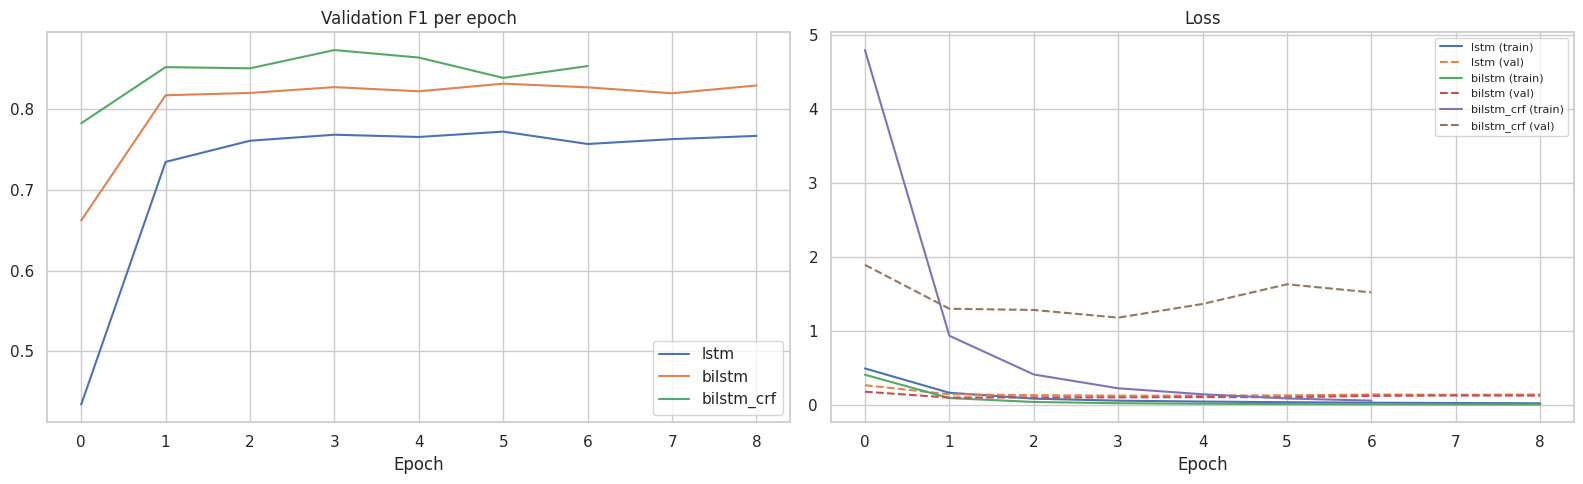

In [15]:
### Training curves
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, h in rnn_histories.items():
    axes[0].plot(h["val_f1"], label=name)
    axes[1].plot(h["train_loss"], label=f"{name} (train)")
    axes[1].plot(h["val_loss"], "--", label=f"{name} (val)")
axes[0].set_title("Validation F1 per epoch"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("rnn_training_curves.png", dpi=150); plt.show()

**What to look for:** plain `LSTM` (uni-directional) typically lags `BiLSTM` since it
only sees left-context when deciding a tag — entities are often disambiguated by a word
that comes *after* them (e.g. a title following a name). `BiLSTM+CRF` should track
`BiLSTM` closely on loss but produce noticeably fewer invalid tag *sequences*, which
shows up as a higher entity-level (not token-level) F1 in the evaluation below.

In [16]:
### Evaluation on the held-out test set (seqeval, entity-level)
rnn_results = {}

for name, model in rnn_models.items():
    is_crf = name == "bilstm_crf"
    y_true, y_pred = predict_tags(model, test_loader, is_crf)

    print(f"\n{'='*20} {name.upper()} {'='*20}")
    print(classification_report(y_true, y_pred, digits=4))

    rnn_results[name] = {
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1_score": f1_score(y_true, y_pred),
    }

with open("rnn_results.json", "w") as f:
    json.dump(rnn_results, f, indent=2)

pd.DataFrame(rnn_results).T


==================== LSTM ====================
              precision    recall  f1-score   support

         LOC     0.7882    0.7892    0.7887      1660
        MISC     0.4928    0.6852    0.5733       702
         ORG     0.4911    0.6807    0.5706      1660
         PER     0.8571    0.5868    0.6967      1595

   micro avg     0.6395    0.6867    0.6623      5617
   macro avg     0.6573    0.6855    0.6573      5617
weighted avg     0.6831    0.6867    0.6712      5617


==================== BILSTM ====================
              precision    recall  f1-score   support

         LOC     0.8627    0.8590    0.8609      1660
        MISC     0.4445    0.7593    0.5608       702
         ORG     0.7338    0.6940    0.7133      1660
         PER     0.8457    0.6527    0.7367      1595

   micro avg     0.7345    0.7392    0.7368      5617
   macro avg     0.7217    0.7412    0.7179      5617
weighted avg     0.7675    0.7392    0.7445      5617


==================== BILSTM_CRF

,precision,recall,f1_score
lstm,0.639529,0.686665,0.662260
bilstm,0.734477,0.739185,0.736823
bilstm_crf,0.779396,0.800071,0.789599


In [17]:
### Quick check: does the CRF actually reduce illegal tag transitions?
def count_illegal_transitions(tag_seqs):
    """Counts cases like I-XXX appearing without a preceding B-XXX/I-XXX of the same type —
    a token-level tagger has no mechanism to prevent this; a CRF is explicitly trained to."""
    illegal = 0
    for seq in tag_seqs:
        prev = "O"
        for tag in seq:
            if tag.startswith("I-"):
                entity = tag.split("-")[1]
                if not (prev == f"B-{entity}" or prev == f"I-{entity}"):
                    illegal += 1
            prev = tag
    return illegal

_, bilstm_preds = predict_tags(rnn_models["bilstm"], test_loader, is_crf=False)
_, crf_preds = predict_tags(rnn_models["bilstm_crf"], test_loader, is_crf=True)

print("Illegal I-tag transitions — BiLSTM:     ", count_illegal_transitions(bilstm_preds))
print("Illegal I-tag transitions — BiLSTM+CRF: ", count_illegal_transitions(crf_preds))

Illegal I-tag transitions — BiLSTM:      309
Illegal I-tag transitions — BiLSTM+CRF:  103


---
## Stage 5 — Fine-Tune a Transformer (DistilBERT)

Instead of learning word representations from scratch (as the LSTM family does),
DistilBERT starts from weights **pretrained on a huge text corpus**, so it already
"understands" English before ever seeing a single CoNLL sentence. Fine-tuning only
needs to adapt that existing understanding to token classification.

> Requires internet + GPU enabled on this notebook (Kaggle: Settings → Accelerator →
> GPU, Internet → On).

In [18]:
hf_model = AutoModelForTokenClassification.from_pretrained(
    CONFIG["transformer_name"], num_labels=NUM_LABELS, id2label=id2label, label2id=label2id
).to(device)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    true_seqs, pred_seqs = [], []
    for pred_row, label_row in zip(preds, labels):
        true_seq, pred_seq = [], []
        for p, l in zip(pred_row, label_row):
            if l != -100:                 # skip special tokens / non-first subwords
                true_seq.append(id2label[l])
                pred_seq.append(id2label[p])
        true_seqs.append(true_seq)
        pred_seqs.append(pred_seq)

    return {
        "precision": precision_score(true_seqs, pred_seqs),
        "recall": recall_score(true_seqs, pred_seqs),
        "f1": f1_score(true_seqs, pred_seqs),
    }

training_args = TrainingArguments(
    output_dir="transformer_checkpoints",
    learning_rate=CONFIG["transformer_lr"],
    per_device_train_batch_size=CONFIG["transformer_train_batch"],
    per_device_eval_batch_size=CONFIG["transformer_eval_batch"],
    num_train_epochs=CONFIG["transformer_epochs"],
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=50,
    report_to="none",
)

# `processing_class` is the current Trainer API (recent `transformers` versions);
# use `tokenizer=hf_tokenizer` instead if your installed version predates that rename.
trainer = Trainer(
    model=hf_model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["validation"],
    processing_class=hf_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
transformer_val_f1 = float(trainer.evaluate(tokenized_ds["validation"])["eval_f1"])
print("Best transformer validation F1:", transformer_val_f1)

model.safetensors:   0%|          | 0.00/263M [00:00<?, ?B/s]

Some weights of DistilBertForTokenClassification were not initialized from the model checkpoint at distilbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,0.068900,0.065853,0.883472,0.890609,0.887026
2,0.045200,0.049844,0.918570,0.920734,0.919650
3,0.029300,0.046069,0.922871,0.930326,0.926584


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Best transformer validation F1: 0.926583975863225


In [19]:
### Evaluation on the held-out test set
test_predictions = trainer.predict(tokenized_ds["test"])
logits, labels = test_predictions.predictions, test_predictions.label_ids
preds = np.argmax(logits, axis=-1)

true_seqs, pred_seqs = [], []
for pred_row, label_row in zip(preds, labels):
    true_seq, pred_seq = [], []
    for p, l in zip(pred_row, label_row):
        if l != -100:
            true_seq.append(id2label[l])
            pred_seq.append(id2label[p])
    true_seqs.append(true_seq)
    pred_seqs.append(pred_seq)

print(classification_report(true_seqs, pred_seqs, digits=4))

transformer_results = {
    "precision": precision_score(true_seqs, pred_seqs),
    "recall": recall_score(true_seqs, pred_seqs),
    "f1_score": f1_score(true_seqs, pred_seqs),
}
with open("transformer_results.json", "w") as f:
    json.dump(transformer_results, f, indent=2)
transformer_results

              precision    recall  f1-score   support

         LOC     0.9163    0.9119    0.9141      1668
        MISC     0.7313    0.7949    0.7618       702
         ORG     0.8494    0.8826    0.8657      1661
         PER     0.9580    0.9462    0.9521      1617

   micro avg     0.8832    0.8985    0.8908      5648
   macro avg     0.8637    0.8839    0.8734      5648
weighted avg     0.8856    0.8985    0.8918      5648



{'precision': np.float64(0.8832231117298991),
 'recall': np.float64(0.8985481586402266),
 'f1_score': np.float64(0.890819729682289)}

---
## Stage 6 — Model selection (validation only) and final held-out test reporting

Select the best architecture using validation entity-span F1. Report all four test metrics for educational comparison, but **never** change the deployment choice based on the test set.

In [20]:
validation_scores = {name: m["f1_score"] for name, m in rnn_val_results.items()}
validation_scores["transformer"] = transformer_val_f1
validation_df = (pd.DataFrame.from_dict(validation_scores, orient="index", columns=["val_entity_f1"])
                 .sort_values("val_entity_f1", ascending=False))
best_model_name = validation_df.index[0]
print("Selected for deployment using validation only:", best_model_name)
display(validation_df)

all_results = {**rnn_results, "transformer": transformer_results}
comparison_df = pd.DataFrame(all_results).T
comparison_df.insert(0, "val_entity_f1", pd.Series(validation_scores))
comparison_df = comparison_df.sort_values("val_entity_f1", ascending=False)
display(comparison_df)
comparison_df.to_csv("model_comparison.csv")

Selected for deployment using validation only: transformer


,val_entity_f1
transformer,0.926584
bilstm_crf,0.872902
bilstm,0.831347
lstm,0.772017


,val_entity_f1,precision,recall,f1_score
transformer,0.926584,0.883223,0.898548,0.890820
bilstm_crf,0.872902,0.779396,0.800071,0.789599
bilstm,0.831347,0.734477,0.739185,0.736823
lstm,0.772017,0.639529,0.686665,0.662260


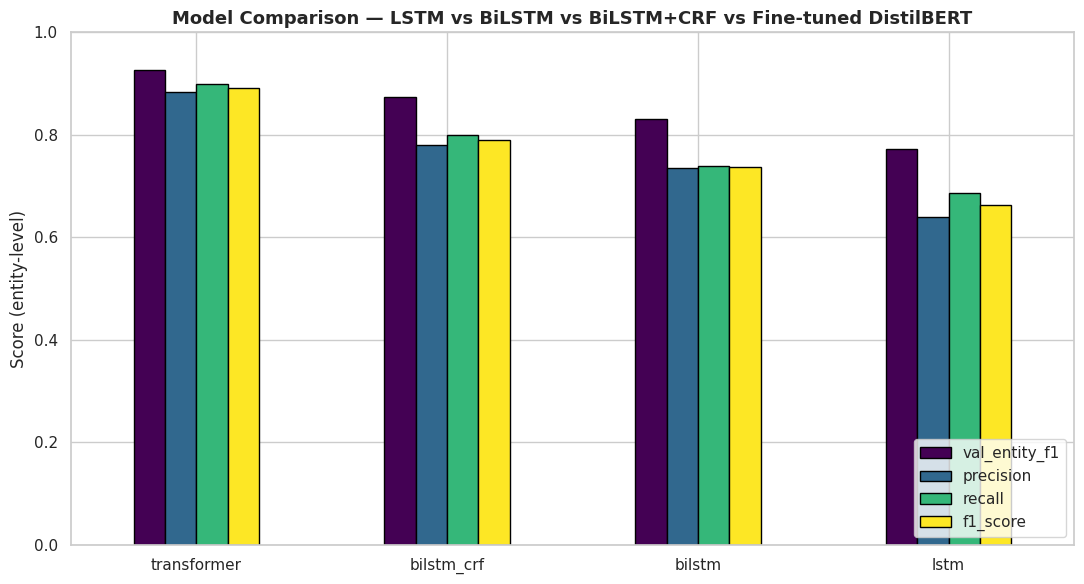

In [21]:
comparison_df.plot(kind="bar", figsize=(11, 6), colormap="viridis", edgecolor="black")
plt.title("Model Comparison — LSTM vs BiLSTM vs BiLSTM+CRF vs Fine-tuned DistilBERT",
          fontsize=13, fontweight="bold")
plt.ylabel("Score (entity-level)"); plt.xticks(rotation=0); plt.ylim(0, 1)
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig("final_model_comparison.png", dpi=150); plt.show()

In [22]:
# IMPORTANT: Best checkpoint decided solely by validation F1, not test F1.
print(f"Selected: {best_model_name}  (validation entity F1={validation_scores[best_model_name]:.4f})")
best_model_info = {
    "best_model": best_model_name,
    "validation_f1": validation_scores,
    "test_results_for_reporting_only": all_results,
}
with open("best_model_info.json", "w") as f:
    json.dump(best_model_info, f, indent=2)

Selected: transformer  (validation entity F1=0.9266)


**Trade-off worth noting in the write-up:** the Transformer usually wins on raw F1
thanks to its pretrained language understanding, but it's also the heaviest and
slowest model to run inference on. `BiLSTM+CRF` is a good middle ground — noticeably
better boundary consistency than plain `BiLSTM` (see the illegal-transition check in
Stage 4) at a fraction of the transformer's parameter count and latency. Which one is
"best" depends on whether the deployment priority is accuracy or latency/cost.

---
## Stage 7 — Export the Best Model for Deployment

Bundles exactly the files the Gradio app in Stage 8 needs into one folder, so nothing
has to be located and copied by hand.

In [23]:
# Export model and preprocessing resources for a separate Gradio process.
# Embedding matrix is essential when reconstructing an RNN architecture.
save_dir = CONFIG["save_dir"]
os.makedirs(save_dir, exist_ok=True)
for name, content in [("word2idx.json", word2idx), ("char2idx.json", char2idx),
                      ("config.json", {**CONFIG, "id2label": id2label, "label2id": label2id}),
                      ("best_model_info.json", best_model_info)]:
    with open(os.path.join(save_dir, name), "w") as f:
        json.dump(content, f, indent=2)
np.save(os.path.join(save_dir, "embedding_matrix.npy"), embedding_matrix)

if best_model_name == "transformer":
    trainer.save_model(os.path.join(save_dir, "transformer"))
    hf_tokenizer.save_pretrained(os.path.join(save_dir, "transformer"))
else:
    shutil.copy2(f"model_{best_model_name}.pt", os.path.join(save_dir, f"model_{best_model_name}.pt"))
print("Saved deployment assets:", os.listdir(save_dir))

Saved deployment assets: ['char2idx.json', 'embedding_matrix.npy', 'config.json', 'best_model_info.json', 'word2idx.json', 'transformer']


#### Gradio interface 

In [30]:
import os
import json

MODEL_DIR = os.path.abspath(CONFIG["save_dir"])

with open(
    os.path.join(MODEL_DIR, "best_model_info.json")
) as f:
    best_info = json.load(f)

print("Model directory:", MODEL_DIR)
print("Best model:", best_info["best_model"])

Model directory: /kaggle/working/deployment_bundle
Best model: transformer


In [ ]:

# ============================================================
# STAGE 8 — NER GRADIO DASHBOARD
# Kaggle Notebook | Professional Dark Interface
# ============================================================

import html
import json
import re
from collections import Counter
from pathlib import Path

import gradio as gr
import torch
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer
)

# ============================================================
# 1. LOAD TRAINED MODEL
# ============================================================

MODEL_DIR = Path("/kaggle/working/deployment_bundle")
TRANSFORMER_DIR = MODEL_DIR / "transformer"

if not (MODEL_DIR / "best_model_info.json").is_file():
    raise FileNotFoundError(
        f"Missing Stage 7 export in {MODEL_DIR}"
    )

with open(
    MODEL_DIR / "best_model_info.json",
    encoding="utf-8"
) as f:
    best_info = json.load(f)

with open(
    MODEL_DIR / "config.json",
    encoding="utf-8"
) as f:
    cfg = json.load(f)

if best_info["best_model"] != "transformer":
    raise ValueError(
        f"Expected transformer, got {best_info['best_model']}"
    )

id2label = {
    int(k): v
    for k, v in cfg["id2label"].items()
}

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

tokenizer = AutoTokenizer.from_pretrained(
    TRANSFORMER_DIR,
    use_fast=True
)

model = AutoModelForTokenClassification.from_pretrained(
    TRANSFORMER_DIR
).to(device)

model.eval()

print(f"DistilBERT loaded successfully on {device}")

# ============================================================
# 2. ENTITY TYPES AND COLORS
# ============================================================

COLORS = {
    "PER": "#F9A8D4",
    "ORG": "#86EFAC",
    "LOC": "#93C5FD",
    "MISC": "#FDE68A"
}

NAMES = {
    "PER": "Person",
    "ORG": "Organization",
    "LOC": "Location",
    "MISC": "Miscellaneous"
}

# ============================================================
# 3. TRANSFORMER INFERENCE
# ============================================================

@torch.inference_mode()
def predict_tags(words):

    all_tags = []
    start = 0

    while start < len(words):

        end = min(start + 100, len(words))

        # Avoid exceeding the 512-subtoken limit
        while end > start + 1:

            probe = tokenizer(
                words[start:end],
                is_split_into_words=True,
                add_special_tokens=True
            )

            if len(probe["input_ids"]) <= 512:
                break

            end -= 1

        batch = words[start:end]

        encoded = tokenizer(
            batch,
            is_split_into_words=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        )

        word_ids = encoded.word_ids(batch_index=0)

        inputs = {
            k: v.to(device)
            for k, v in encoded.items()
        }

        outputs = model(**inputs)

        predictions = (
            outputs.logits.argmax(-1)[0]
            .cpu()
            .tolist()
        )

        tags = ["O"] * len(batch)
        seen = set()

        for word_id, pred in zip(
            word_ids, predictions
        ):

            if word_id is not None and word_id not in seen:

                tags[word_id] = id2label[int(pred)]
                seen.add(word_id)

        all_tags.extend(tags)
        start = end

    return all_tags


# ============================================================
# 4. CONVERT BIO TAGS INTO ENTITY SPANS
# ============================================================

def get_entities(text):

    matches = list(
        re.finditer(
            r"\w+(?:[’'-]\w+)*|[^\w\s]",
            text,
            flags=re.UNICODE
        )
    )

    words = [m.group(0) for m in matches]
    tags = predict_tags(words)

    entities = []
    current = None

    for match, tag in zip(matches, tags):

        if tag == "O" or "-" not in tag:

            if current is not None:
                entities.append(current)
                current = None

            continue

        prefix, kind = tag.split("-", 1)

        if kind not in COLORS:

            if current is not None:
                entities.append(current)
                current = None

            continue

        if (
            current is not None
            and prefix == "I"
            and current["entity"] == kind
        ):

            current["end"] = match.end()

        else:

            if current is not None:
                entities.append(current)

            current = {
                "entity": kind,
                "start": match.start(),
                "end": match.end()
            }

    if current is not None:
        entities.append(current)

    return entities


# ============================================================
# 5. STATISTICS DASHBOARD
# ============================================================

def statistics_html(entities):

    counts = Counter(
        e["entity"] for e in entities
    )

    values = [
        ("TOTAL", len(entities), "#60A5FA")
    ]

    values += [
        (k, counts.get(k, 0), COLORS[k])
        for k in COLORS
    ]

    cards = "".join(
        f'<div class="stat">'
        f'<div class="stat-name">{label}</div>'
        f'<div class="stat-number" style="color:{color}">'
        f'{number}</div></div>'
        for label, number, color in values
    )

    return f'<div class="stats">{cards}</div>'


# ============================================================
# 6. ENTITY DETAILS TABLE
# ============================================================

def details_html(text, entities):

    if not entities:
        return (
            '<div class="empty">'
            'No entities detected yet.'
            '</div>'
        )

    rows = "".join(
        '<tr>'
        f'<td>{html.escape(text[e["start"]:e["end"]])}</td>'
        f'<td><span class="tag" '
        f'style="background:{COLORS[e["entity"]]}">'
        f'{e["entity"]}</span></td>'
        f'<td>{NAMES[e["entity"]]}</td>'
        '</tr>'
        for e in entities
    )

    return (
        '<div class="table-scroll">'
        '<table class="entity-table">'
        '<thead><tr>'
        '<th>Entity</th>'
        '<th>Tag</th>'
        '<th>Category</th>'
        '</tr></thead>'
        f'<tbody>{rows}</tbody>'
        '</table></div>'
    )


# ============================================================
# 7. ANALYSIS AND RESET FUNCTIONS
# ============================================================

def analyze(text):

    if not (text or "").strip():

        return (
            {"text": "", "entities": []},
            statistics_html([]),
            details_html("", [])
        )

    entities = get_entities(text)

    return (
        {
            "text": text,
            "entities": entities
        },
        statistics_html(entities),
        details_html(text, entities)
    )


def clear():

    return (
        "",
        {"text": "", "entities": []},
        statistics_html([]),
        details_html("", [])
    )


# ============================================================
# 8. PROFESSIONAL DARK THEME
# ============================================================

CSS = """
:root {
    color-scheme: dark;
}

body,
.gradio-container {
    background: #080e1c !important;
    color: #edf3ff !important;
}

.gradio-container {
    max-width: 1220px !important;
    margin: auto !important;
    padding: 24px !important;
}

/* HEADER */

.hero {
    background: linear-gradient(
        115deg,
        #142a4b,
        #111b32 65%,
        #171b35
    );

    border: 1px solid #324567;
    border-radius: 22px;
    padding: 32px;
    margin-bottom: 20px;
}

.hero .eyebrow {
    color: #69e2e5;
    font-size: 12px;
    font-weight: 800;
    letter-spacing: 2px;
}

.hero h1 {
    font-size: clamp(28px, 3vw, 42px);
    font-weight: 800;
    color: #f8fbff !important;
    margin: 12px 0;
}

.hero p {
    color: #a8bfda !important;
    font-size: 15px;
    line-height: 1.7;
    max-width: 780px;
}

.chips {
    display: flex;
    gap: 8px;
    flex-wrap: wrap;
    margin-top: 18px;
}

.chips span {
    border: 1px solid #3b5679;
    border-radius: 100px;
    background: #1c3150;
    padding: 7px 12px;
    color: #dbeafe;
    font-size: 12px;
}

/* PANELS */

#input-panel,
#output-panel {
    background: #101a2b !important;
    border: 1px solid #2d405e !important;
    border-radius: 18px !important;
    padding: 18px !important;
}

#input-panel textarea {
    background: #0c1525 !important;
    color: #f1f6ff !important;
    border: 1px solid #334967 !important;
}

/* BUTTONS */

#run-btn {
    background: linear-gradient(
        105deg,
        #2563eb,
        #6558e8
    ) !important;

    color: white !important;
    font-weight: 800 !important;
    border-radius: 12px !important;
    min-height: 48px;
}

#reset-btn {
    background: #1b2b45 !important;
    color: #e6eefb !important;
    border-radius: 12px !important;
    min-height: 48px;
}

/* HIGHLIGHTED ENTITIES */

#highlights {
    background: #0c1525 !important;
    border: 1px solid #334967 !important;
    border-radius: 12px !important;
}

/* TITLES */

.section {
    font-size: 18px;
    font-weight: 750;
    color: #f3f7ff !important;
    margin: 12px 0;
}

/* ENTITY LEGEND */

.legend {
    display: flex;
    flex-wrap: wrap;
    gap: 8px;
    margin: 10px 0 16px;
}

.legend span,
.tag {
    border-radius: 8px;
    padding: 6px 10px;
    color: #111827;
    font-weight: 800;
    font-size: 12px;
}

/* STATISTICS */

.stats {
    display: grid;
    grid-template-columns:
        repeat(5, minmax(0, 1fr));
    gap: 10px;
}

.stat {
    background: #0c1729;
    border: 1px solid #293d59;
    border-radius: 14px;
    padding: 14px;
    text-align: center;
}

.stat-name {
    font-size: 11px;
    color: #a9bbd2;
    font-weight: 800;
    letter-spacing: 0.5px;
}

.stat-number {
    font-size: 28px;
    font-weight: 850;
    margin-top: 7px;
}

/* ENTITY TABLE */

.table-scroll {
    overflow-x: auto;
    border: 1px solid #2b3d58;
    border-radius: 12px;
}

.entity-table {
    width: 100%;
    border-collapse: collapse;
    background: #101a2c;
    color: #e7eefc;
}

.entity-table th {
    background: #1a2b46;
    color: #bfd1e5;
    text-align: left;
    font-size: 13px;
    padding: 13px;
}

.entity-table td {
    border-top: 1px solid #2b3d58;
    padding: 12px;
    font-size: 14px;
}

/* EMPTY STATE */

.empty {
    background: #101a2c;
    color: #96abc5;
    padding: 24px;
    text-align: center;
    border-radius: 12px;
}

/* FOOTER */

.footer {
    text-align: center;
    color: #7f96b5;
    padding: 20px;
    font-size: 12px;
}

/* RESPONSIVE */

@media (max-width: 850px) {
    .stats {
        grid-template-columns: repeat(3, 1fr);
    }
}

@media (max-width: 520px) {
    .stats {
        grid-template-columns: repeat(2, 1fr);
    }

    .hero {
        padding: 20px;
    }
}

/* FIX: Entity Details Table Text Visibility */

.entity-table,
.entity-table tbody,
.entity-table tr,
.entity-table td {
    color: #F8FAFC !important;
}

.entity-table tbody td {
    background-color: #101A2C !important;
    font-size: 14px !important;
    font-weight: 500 !important;
    opacity: 1 !important;
}

.entity-table tbody tr:hover td {
    background-color: #1E304D !important;
    color: #FFFFFF !important;
}

.entity-table th {
    background-color: #1A2B46 !important;
    color: #E2E8F0 !important;
    font-weight: 700 !important;
}

.entity-table .tag {
    color: #111827 !important;
    font-weight: 800 !important;
}

"""


# ============================================================
# 9. HEADER AND LEGEND
# ============================================================

HEADER = """
<div class="hero">

    <div class="eyebrow">
        NLP LAB · INTERACTIVE AI DEMO
    </div>

    <h1>
        Named Entity Recognition
        <br>
        System
    </h1>

    <p>
        Identify people, organizations, locations and
        miscellaneous entities in English text,
        powered by a fine-tuned DistilBERT model.
    </p>

    <div class="chips">
        <span>CoNLL-2003</span>
        <span>DistilBERT</span>
        <span>Token Classification</span>
        <span>Live Inference</span>
    </div>

</div>
"""

legend = '<div class="legend">' + "".join(
    f'<span style="background:{COLORS[k]}">'
    f'{k} · {NAMES[k]}</span>'
    for k in COLORS
) + '</div>'


# ============================================================
# 10. BUILD GRADIO INTERFACE
# ============================================================

# Theme and CSS are defined in Blocks(),
# not in launch(), for your installed Gradio version.

with gr.Blocks(
    title="NER Studio | Named Entity Recognition",
    theme=gr.themes.Base(
        primary_hue="blue",
        neutral_hue="slate"
    ),
    css=CSS
) as demo:

    gr.HTML(HEADER)

    with gr.Row(equal_height=False):

        # INPUT PANEL

        with gr.Column(
            scale=5,
            min_width=320,
            elem_id="input-panel"
        ):

            gr.HTML(
                '<div class="section">'
                'Input Workspace'
                '</div>'
            )

            gr.Markdown(
                "Enter an English sentence or paragraph."
            )

            text_input = gr.Textbox(
                label="Input text",
                show_label=False,
                lines=9,
                max_lines=15,
                placeholder="Enter English text...",
                value=(
                    "Elon Musk visited London and met "
                    "executives from Microsoft and Google."
                )
            )

            with gr.Row():

                run_button = gr.Button(
                    "Analyze Entities",
                    variant="primary",
                    scale=3,
                    elem_id="run-btn"
                )

                clear_button = gr.Button(
                    "Clear",
                    scale=1,
                    elem_id="reset-btn"
                )

            gr.Markdown(
                "**Active model:** Fine-tuned DistilBERT"
            )

        # OUTPUT PANEL

        with gr.Column(
            scale=6,
            min_width=320,
            elem_id="output-panel"
        ):

            gr.HTML(
                '<div class="section">'
                'Entity Visualization'
                '</div>'
            )

            highlights = gr.HighlightedText(
                label="Detected entities",
                show_label=False,
                color_map=COLORS,
                show_legend=False,
                value={
                    "text": "Results will appear here.",
                    "entities": []
                },
                elem_id="highlights"
            )

            gr.HTML(legend)

            gr.HTML(
                '<div class="section">'
                'Detection Overview'
                '</div>'
            )

            stats = gr.HTML(
                statistics_html([])
            )

    # ENTITY DETAILS

    gr.HTML(
        '<div class="section">'
        'Detected Entity Details'
        '</div>'
    )

    details = gr.HTML(
        details_html("", [])
    )

    # EXAMPLE SENTENCES

    gr.HTML(
        '<div class="section">'
        'Try Example Sentences'
        '</div>'
    )

    gr.Examples(
        examples=[
            [
                "Barack Obama visited Paris and met "
                "executives from Microsoft."
            ],
            [
                "Apple CEO Tim Cook attended "
                "a conference in London."
            ],
            [
                "The United Nations organized "
                "a meeting in Geneva."
            ],
            [
                "Lionel Messi played for Barcelona "
                "before moving to Paris."
            ]
        ],
        inputs=text_input
    )

    gr.HTML(
        '<div class="footer">'
        'NER Project · CoNLL-2003 · '
        'Fine-tuned Transformer'
        '</div>'
    )

    # BUTTON EVENTS

    run_button.click(
        fn=analyze,
        inputs=text_input,
        outputs=[
            highlights,
            stats,
            details
        ]
    )

    text_input.submit(
        fn=analyze,
        inputs=text_input,
        outputs=[
            highlights,
            stats,
            details
        ]
    )

    clear_button.click(
        fn=clear,
        outputs=[
            text_input,
            highlights,
            stats,
            details
        ]
    )


# ============================================================
# 11. LAUNCH INTERFACE
# ============================================================

# Do not pass theme or css to launch().

demo.launch(
    share=True,
    inline=True,
    debug=True
)


/tmp/ipykernel_50/2035165010.py:652: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(
/tmp/ipykernel_50/2035165010.py:652: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(


DistilBERT loaded successfully on cuda
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://fa917adab241a7b78f.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
